In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import random
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Load MNIST data
data = np.load('mnist.npz')
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']

In [3]:
print(x_train.shape)

(60000, 28, 28)


In [4]:
# Normalize

# Normalize using min–max range
m, n = np.max(x_train), np.min(x_train)
normalised_value = m-n
print(f"Max pixel value: {m}")
print(f"Min pixel value: {n}")
x_train, x_test = x_train/normalised_value, x_test/normalised_value

Max pixel value: 255
Min pixel value: 0


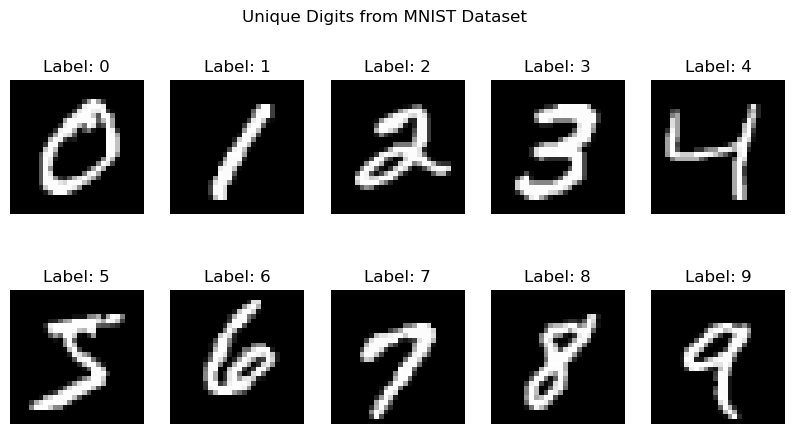

In [5]:
# Visualize unique digits
unique_labels, idx = np.unique(y_train, return_index=True)
fig, ax = plt.subplots(2, 5, figsize=(10, 5))
for i, label in enumerate(unique_labels):
    ax.flat[i].imshow(x_train[idx[i]], cmap='gray')
    ax.flat[i].set_title(f"Label: {label}")
    ax.flat[i].axis('off')
plt.suptitle("Unique Digits from MNIST Dataset")
plt.show()

In [6]:
# --------------------------------------------------
# 1. Model 1 - Learning Rate = 0.001
# --------------------------------------------------

model1 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model1.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history1 = model1.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss1, acc1 = model1.evaluate(x_test, y_test, verbose=2)
print(f"Model 1 Test Accuracy: {acc1 * 100:.2f}%")


Epoch 1/10
1500/1500 - 13s - 9ms/step - accuracy: 0.2875 - loss: 2.1215 - val_accuracy: 0.6554 - val_loss: 1.7807
Epoch 2/10
1500/1500 - 16s - 10ms/step - accuracy: 0.5971 - loss: 1.5241 - val_accuracy: 0.7912 - val_loss: 1.0023
Epoch 3/10
1500/1500 - 7s - 5ms/step - accuracy: 0.7087 - loss: 1.0080 - val_accuracy: 0.8462 - val_loss: 0.6480
Epoch 4/10
1500/1500 - 10s - 7ms/step - accuracy: 0.7709 - loss: 0.7690 - val_accuracy: 0.8725 - val_loss: 0.5058
Epoch 5/10
1500/1500 - 8s - 6ms/step - accuracy: 0.8023 - loss: 0.6541 - val_accuracy: 0.8823 - val_loss: 0.4374
Epoch 6/10
1500/1500 - 8s - 6ms/step - accuracy: 0.8255 - loss: 0.5797 - val_accuracy: 0.8898 - val_loss: 0.3969
Epoch 7/10
1500/1500 - 11s - 7ms/step - accuracy: 0.8402 - loss: 0.5329 - val_accuracy: 0.8973 - val_loss: 0.3667
Epoch 8/10
1500/1500 - 11s - 7ms/step - accuracy: 0.8526 - loss: 0.4979 - val_accuracy: 0.9040 - val_loss: 0.3454
Epoch 9/10
1500/1500 - 22s - 14ms/step - accuracy: 0.8614 - loss: 0.4694 - val_accuracy: 0

In [7]:
# --------------------------------------------------
# 2. Model 2 - Learning Rate = 0.005
# --------------------------------------------------

model2 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model2.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model2.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss2, acc2 = model2.evaluate(x_test, y_test, verbose=2)
print(f"Model 2 Test Accuracy: {acc2 * 100:.2f}%")

Epoch 1/10
1500/1500 - 9s - 6ms/step - accuracy: 0.6044 - loss: 1.2870 - val_accuracy: 0.8802 - val_loss: 0.4536
Epoch 2/10
1500/1500 - 10s - 7ms/step - accuracy: 0.8446 - loss: 0.5143 - val_accuracy: 0.9093 - val_loss: 0.3172
Epoch 3/10
1500/1500 - 10s - 6ms/step - accuracy: 0.8804 - loss: 0.4059 - val_accuracy: 0.9201 - val_loss: 0.2702
Epoch 4/10
1500/1500 - 10s - 7ms/step - accuracy: 0.8989 - loss: 0.3468 - val_accuracy: 0.9287 - val_loss: 0.2406
Epoch 5/10
1500/1500 - 8s - 6ms/step - accuracy: 0.9080 - loss: 0.3093 - val_accuracy: 0.9352 - val_loss: 0.2159
Epoch 6/10
1500/1500 - 7s - 5ms/step - accuracy: 0.9184 - loss: 0.2777 - val_accuracy: 0.9414 - val_loss: 0.1971
Epoch 7/10
1500/1500 - 8s - 5ms/step - accuracy: 0.9251 - loss: 0.2548 - val_accuracy: 0.9474 - val_loss: 0.1814
Epoch 8/10
1500/1500 - 7s - 5ms/step - accuracy: 0.9304 - loss: 0.2340 - val_accuracy: 0.9515 - val_loss: 0.1691
Epoch 9/10
1500/1500 - 7s - 5ms/step - accuracy: 0.9359 - loss: 0.2176 - val_accuracy: 0.9538

In [8]:

# --------------------------------------------------
# 3. Model 3 - Learning Rate = 0.01
# --------------------------------------------------

model3 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
model3.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history3 = model3.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss3, acc3 = model3.evaluate(x_test, y_test, verbose=2)
print(f"Model 3 Test Accuracy: {acc3 * 100:.2f}%")

Epoch 1/10
1500/1500 - 9s - 6ms/step - accuracy: 0.7264 - loss: 0.8916 - val_accuracy: 0.9089 - val_loss: 0.3243
Epoch 2/10
1500/1500 - 7s - 5ms/step - accuracy: 0.8901 - loss: 0.3747 - val_accuracy: 0.9324 - val_loss: 0.2349
Epoch 3/10
1500/1500 - 11s - 7ms/step - accuracy: 0.9146 - loss: 0.2910 - val_accuracy: 0.9425 - val_loss: 0.1973
Epoch 4/10
1500/1500 - 7s - 5ms/step - accuracy: 0.9293 - loss: 0.2421 - val_accuracy: 0.9512 - val_loss: 0.1713
Epoch 5/10
1500/1500 - 13s - 8ms/step - accuracy: 0.9384 - loss: 0.2108 - val_accuracy: 0.9564 - val_loss: 0.1505
Epoch 6/10
1500/1500 - 12s - 8ms/step - accuracy: 0.9446 - loss: 0.1863 - val_accuracy: 0.9603 - val_loss: 0.1360
Epoch 7/10
1500/1500 - 17s - 11ms/step - accuracy: 0.9497 - loss: 0.1697 - val_accuracy: 0.9629 - val_loss: 0.1271
Epoch 8/10
1500/1500 - 16s - 11ms/step - accuracy: 0.9540 - loss: 0.1547 - val_accuracy: 0.9650 - val_loss: 0.1195
Epoch 9/10
1500/1500 - 17s - 11ms/step - accuracy: 0.9569 - loss: 0.1433 - val_accuracy: 

In [9]:
# --------------------------------------------------
# 4. Model 4 - Learning Rate = 0.05
# --------------------------------------------------

model4 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
model4.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.05),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history4 = model4.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss4, acc4 = model4.evaluate(x_test, y_test, verbose=2)
print(f"Model 4 Test Accuracy: {acc4 * 100:.2f}%")


Epoch 1/10
1500/1500 - 12s - 8ms/step - accuracy: 0.8688 - loss: 0.4317 - val_accuracy: 0.9470 - val_loss: 0.1777
Epoch 2/10
1500/1500 - 19s - 12ms/step - accuracy: 0.9420 - loss: 0.1922 - val_accuracy: 0.9629 - val_loss: 0.1232
Epoch 3/10
1500/1500 - 21s - 14ms/step - accuracy: 0.9569 - loss: 0.1448 - val_accuracy: 0.9673 - val_loss: 0.1106
Epoch 4/10
1500/1500 - 21s - 14ms/step - accuracy: 0.9641 - loss: 0.1171 - val_accuracy: 0.9691 - val_loss: 0.0979
Epoch 5/10
1500/1500 - 19s - 13ms/step - accuracy: 0.9699 - loss: 0.0986 - val_accuracy: 0.9722 - val_loss: 0.0933
Epoch 6/10
1500/1500 - 13s - 9ms/step - accuracy: 0.9739 - loss: 0.0832 - val_accuracy: 0.9747 - val_loss: 0.0865
Epoch 7/10
1500/1500 - 15s - 10ms/step - accuracy: 0.9764 - loss: 0.0759 - val_accuracy: 0.9759 - val_loss: 0.0833
Epoch 8/10
1500/1500 - 11s - 7ms/step - accuracy: 0.9796 - loss: 0.0660 - val_accuracy: 0.9758 - val_loss: 0.0838
Epoch 9/10
1500/1500 - 17s - 11ms/step - accuracy: 0.9815 - loss: 0.0593 - val_accu

In [10]:
# --------------------------------------------------
# 5. Model 5 - Learning Rate = 0.1
# --------------------------------------------------

model5 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
model5.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history5 = model5.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss5, acc5 = model5.evaluate(x_test, y_test, verbose=2)
print(f"Model 5 Test Accuracy: {acc5 * 100:.2f}%")


Epoch 1/10
1500/1500 - 9s - 6ms/step - accuracy: 0.8887 - loss: 0.3614 - val_accuracy: 0.9538 - val_loss: 0.1495
Epoch 2/10
1500/1500 - 8s - 6ms/step - accuracy: 0.9495 - loss: 0.1645 - val_accuracy: 0.9692 - val_loss: 0.1044
Epoch 3/10
1500/1500 - 13s - 9ms/step - accuracy: 0.9634 - loss: 0.1225 - val_accuracy: 0.9701 - val_loss: 0.1025
Epoch 4/10
1500/1500 - 17s - 11ms/step - accuracy: 0.9695 - loss: 0.1003 - val_accuracy: 0.9752 - val_loss: 0.0840
Epoch 5/10
1500/1500 - 13s - 8ms/step - accuracy: 0.9729 - loss: 0.0864 - val_accuracy: 0.9753 - val_loss: 0.0852
Epoch 6/10
1500/1500 - 13s - 8ms/step - accuracy: 0.9762 - loss: 0.0775 - val_accuracy: 0.9743 - val_loss: 0.0865
Epoch 7/10
1500/1500 - 23s - 15ms/step - accuracy: 0.9782 - loss: 0.0684 - val_accuracy: 0.9763 - val_loss: 0.0792
Epoch 8/10
1500/1500 - 16s - 11ms/step - accuracy: 0.9802 - loss: 0.0632 - val_accuracy: 0.9761 - val_loss: 0.0819
Epoch 9/10
1500/1500 - 10s - 6ms/step - accuracy: 0.9832 - loss: 0.0534 - val_accuracy:

In [11]:

print("\nFinal Test Accuracy Comparison:")

print(f"Learning Rate 0.001 : {acc1 * 100:.2f}%")
print(f"Learning Rate 0.005 : {acc2 * 100:.2f}%")
print(f"Learning Rate 0.01  : {acc3 * 100:.2f}%")
print(f"Learning Rate 0.05  : {acc4 * 100:.2f}%")
print(f"Learning Rate 0.1   : {acc5 * 100:.2f}%")


Final Test Accuracy Comparison:
Learning Rate 0.001 : 91.22%
Learning Rate 0.005 : 95.46%
Learning Rate 0.01  : 96.82%
Learning Rate 0.05  : 97.85%
Learning Rate 0.1   : 97.92%


Enter image index (0-9999):  2


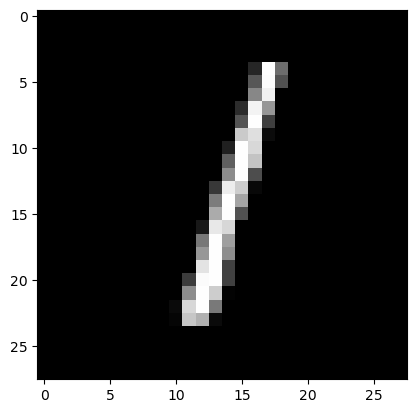

Predicted Digit: 1
Actual Digit: 1


In [12]:
# Predict random test image
# n = random.randint(0, len(x_test)-1)
# plt.imshow(x_test[n], cmap='gray')
# plt.title("Test Image")
# plt.show()
# pred = np.argmax(model3.predict(np.expand_dims(x_test[n], axis=0))[0])
# print("Predicted Digit:", pred)
image_index = int(input("Enter image index (0-9999): "))

plt.imshow(x_test[image_index], cmap='gray')
plt.show()

prediction = model3.predict(x_test[image_index].reshape(1, 28, 28), verbose=0)

print("Predicted Digit:", np.argmax(prediction))
print("Actual Digit:", y_test[image_index])

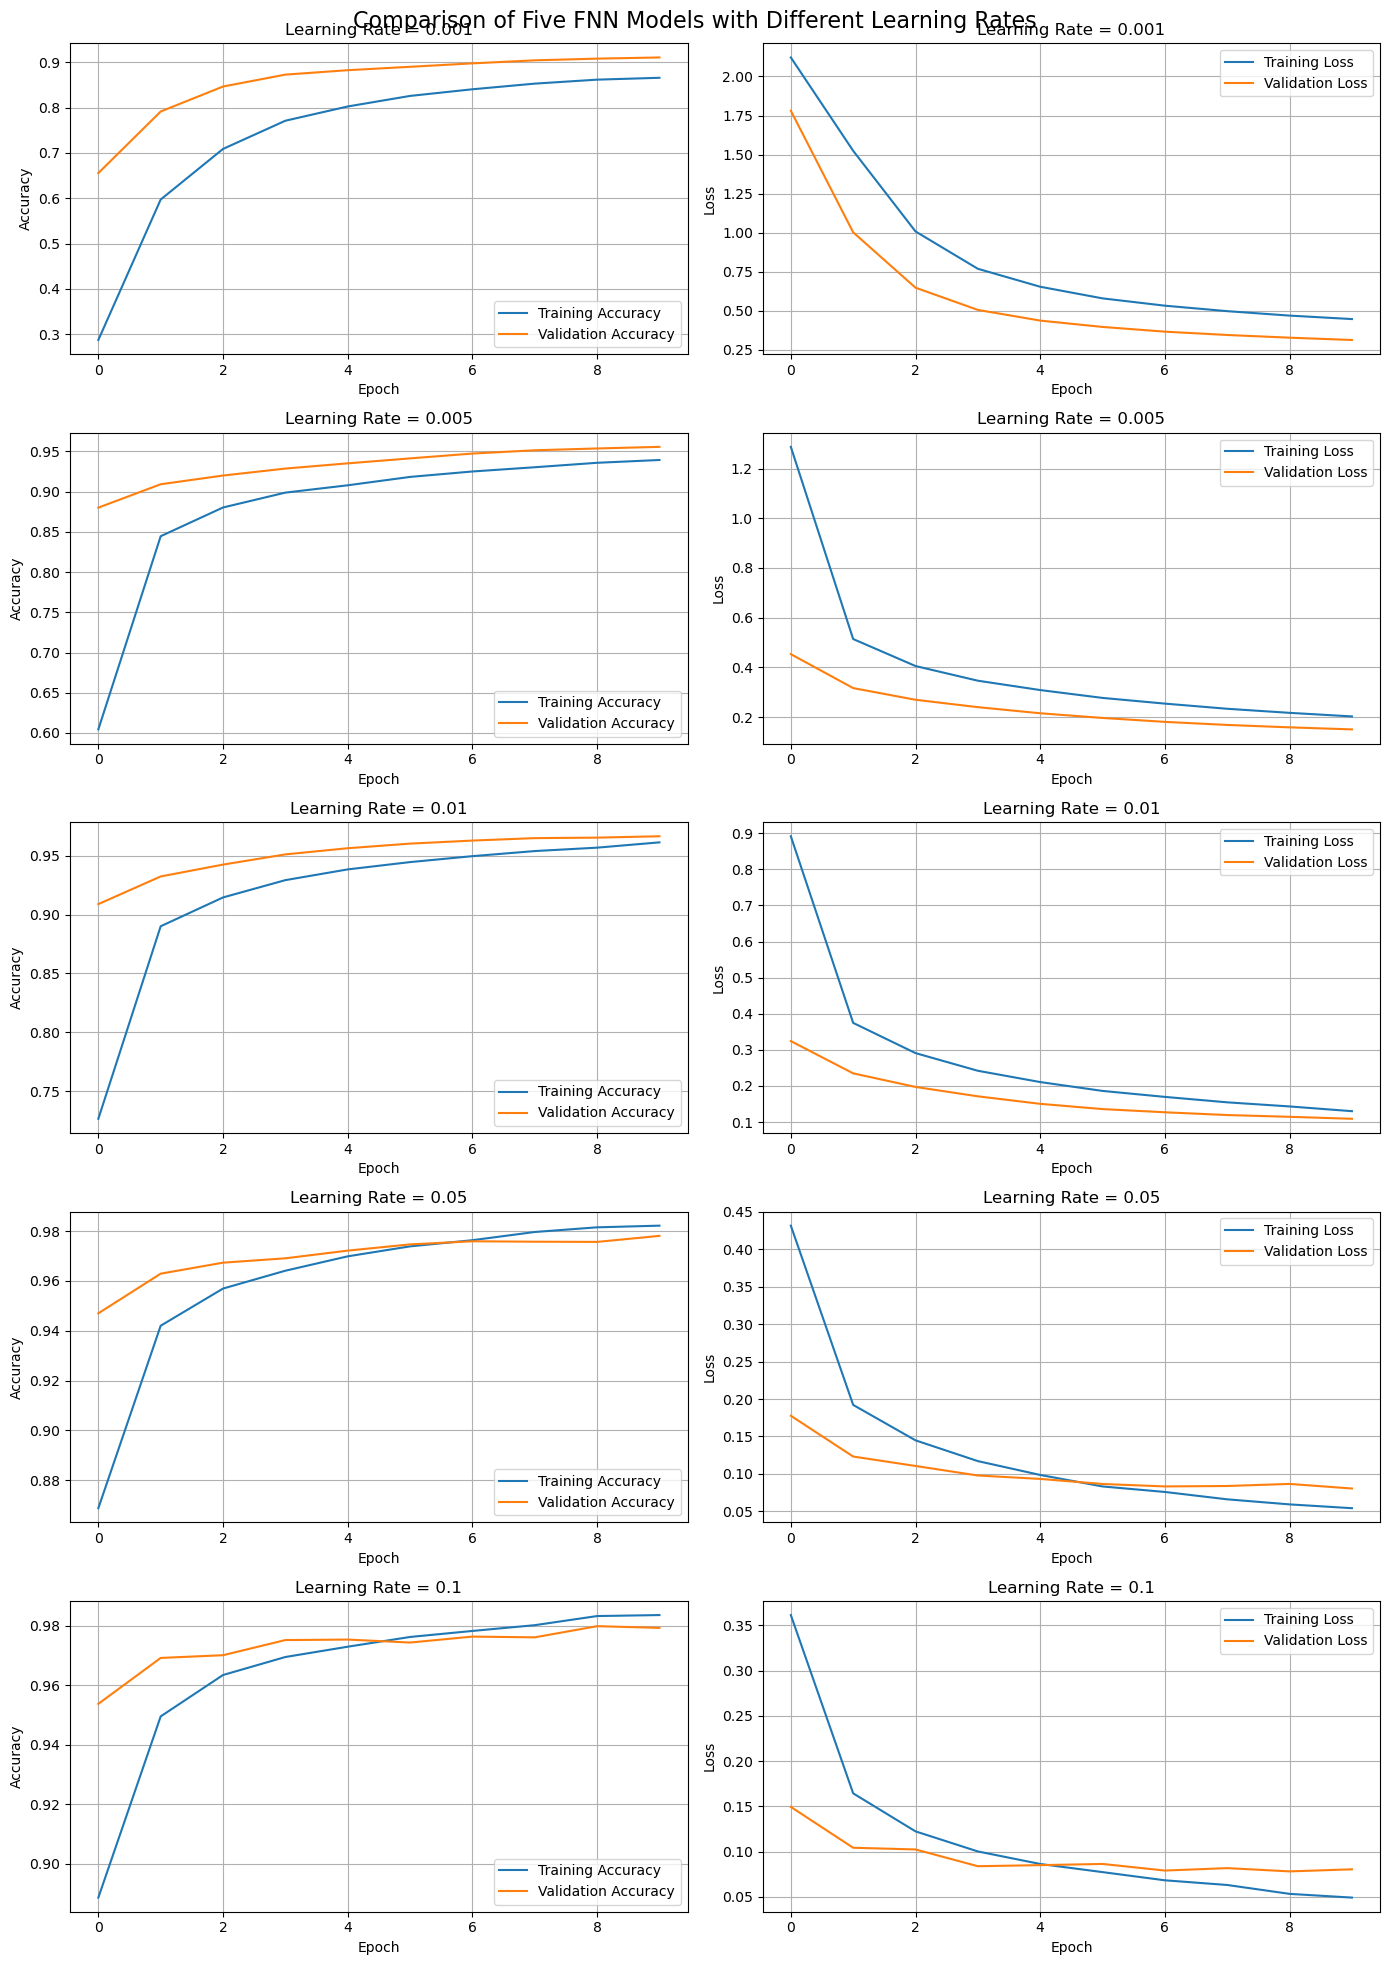

In [13]:
import matplotlib.pyplot as plt

# Store the histories of all five models
histories = [history1, history2, history3, history4, history5]

learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]

# Create 5 rows and 2 columns of subplots
fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for i, history in enumerate(histories):

    # Training and validation accuracy
    axes[i, 0].plot(history.history['accuracy'], label='Training Accuracy')
    axes[i, 0].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[i, 0].set_title(f'Learning Rate = {learning_rates[i]}')
    axes[i, 0].set_xlabel('Epoch')
    axes[i, 0].set_ylabel('Accuracy')
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    # Training and validation loss
    axes[i, 1].plot(history.history['loss'], label='Training Loss')
    axes[i, 1].plot(history.history['val_loss'], label='Validation Loss')
    axes[i, 1].set_title(f'Learning Rate = {learning_rates[i]}')
    axes[i, 1].set_xlabel('Epoch')
    axes[i, 1].set_ylabel('Loss')
    axes[i, 1].legend()
    axes[i, 1].grid(True)

plt.suptitle('Comparison of Five FNN Models with Different Learning Rates',
             fontsize=16)

plt.tight_layout()
plt.show()